# 02 — Affidabilità delle stime

Materiale per il capitolo di **validazione del preprocessing**: quanto ci si può fidare
delle stime del notebook `01`. Tre verifiche — accuratezza su profili sintetici a parametri
noti, sensibilità a rumore/cutoff/soglie, coerenza sui dati reali.

In [1]:
# --- Grafici interattivi (zoom, pan, salvataggio dalla toolbar) ---------------
# Il backend `widget` di ipympl rende zoomabili le figure matplotlib direttamente
# nel notebook, senza cambiare una riga del codice di disegno. Se ipympl non e'
# installato si ricade sul backend statico `inline`, cosi' il notebook resta
# eseguibile ovunque; impostare MPL_STATIC=1 forza il comportamento statico.
import os

from IPython import get_ipython

_ip = get_ipython()
if os.environ.get("MPL_STATIC") or _ip is None:
    _BACKEND = "inline"
else:
    try:
        import ipympl  # noqa: F401
        _BACKEND = "widget"
    except ImportError:
        _BACKEND = "inline"
if _ip is not None:
    _ip.run_line_magic("matplotlib", _BACKEND)

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

DATA_RAW = ROOT / "data" / "raw" / "dati_tesi"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from src.preprocessing import (
    PreprocessingConfig,
    analyze_joint_movement,
    load_position_data,
    segment_movements,
)
from src.trajectory_models import generate_trapezoidal_profile

print(f"backend matplotlib: {_BACKEND}"
      + ("  (grafici interattivi)" if _BACKEND == "widget" else "  (statico)"))

/home/lorenzo/introb/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


backend matplotlib: inline  (statico)


## 1. Accuratezza su profili sintetici

Su un segnale generato analiticamente i parametri veri sono noti, quindi l'errore della
pipeline è misurabile direttamente. La griglia copre entrambi i versi, rampe lunghe e
corte, e i parametri tipici del MyCobot280.

In [2]:
FS_SINT = 100.0          # frequenza di campionamento dei sintetici
CUTOFF_SINT = 6.0        # cutoff proporzionato: fs/cutoff ~ 17
RUMORE = 1.4e-3          # quantizzazione dell'encoder del MyCobot280

griglia = [
    # delta_q, vmax, amax, descrizione
    (2.5, 1.5, 3.0, "riferimento"),
    (-2.5, 1.5, 3.0, "verso negativo"),
    (4.16, 1.318, 5.81, "parametri reali, comando 50"),
    (4.0, 1.0, 4.0, "plateau lungo"),
    (3.0, 2.0, 2.5, "plateau corto"),
    (1.5, 1.5, 3.0, "spostamento ridotto"),
]

righe = []
for delta_q, vmax_vero, amax_vero, descrizione in griglia:
    t, q, info = generate_trapezoidal_profile(
        q0=0.0, delta_q=delta_q, vmax=vmax_vero, amax=amax_vero,
        fs=FS_SINT, t_pre=0.5, t_post=0.5, noise_std=RUMORE, seed=0,
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = analyze_joint_movement(time=t, position=q, fs=FS_SINT,
                                     cutoff_hz=CUTOFF_SINT)
    righe.append({
        "caso": descrizione,
        "delta_q": delta_q,
        "profilo vero": info["profile_type"],
        "profilo stimato": res.profile_type,
        "vmax vero": info["v_peak"],
        "vmax stimata": res.vmax_est,
        "err vmax %": 100 * abs(res.vmax_est - info["v_peak"]) / info["v_peak"]
                      if res.vmax_est else np.nan,
        "amax vero": amax_vero,
        "amax stimata": res.amax_est,
        "err amax %": 100 * abs(res.amax_est - amax_vero) / amax_vero
                      if res.amax_est else np.nan,
    })

accuratezza = pd.DataFrame(righe).round(4)
accuratezza.to_csv(TABLES / "02_accuratezza_sintetici.csv", index=False)
accuratezza

,caso,delta_q,profilo vero,profilo stimato,vmax vero,vmax stimata,err vmax %,amax vero,amax stimata,err amax %
0,riferimento,2.50,trapezoidal,trapezoidal,1.500,1.5013,0.0884,3.00,2.9843,0.5248
1,verso negativo,-2.50,trapezoidal,trapezoidal,1.500,1.4996,0.0234,3.00,3.0060,0.1999
2,"parametri reali, comando 50",4.16,trapezoidal,trapezoidal,1.318,1.3182,0.0168,5.81,5.8414,0.5404
3,plateau lungo,4.00,trapezoidal,trapezoidal,1.000,1.0004,0.0372,4.00,3.9770,0.5740
4,plateau corto,3.00,trapezoidal,trapezoidal,2.000,1.9999,0.0055,2.50,2.5032,0.1292
5,spostamento ridotto,1.50,trapezoidal,trapezoidal,1.500,1.5014,0.0955,3.00,2.9622,1.2588


Il profilo è classificato correttamente in tutti i casi e, con un cutoff proporzionato alla
frequenza di campionamento, entrambi i parametri restano dentro la tolleranza del 5%.
`vmax` è praticamente esatta perché è una media su un plateau lungo; `amax` porta un errore
maggiore perché dipende dalla curvatura delle rampe, che il filtro smussa.

## 2. Sensibilità: rumore, frequenza di taglio, soglie

Si fa variare un fattore per volta e si guarda quanto si spostano le stime. Solo il cutoff
produce una figura, perché è l'unico caso in cui la forma della curva guida una decisione.

In [3]:
# --- rumore: quanto degradano le stime al crescere del rumore di misura -----
LIVELLI = [0.0, 3e-4, 7e-4, 1.4e-3, 3e-3, 7e-3]   # rad
VMAX_VERO, AMAX_VERO, DELTA_Q = 1.5, 3.0, 2.5

righe_rumore = []
for rumore in LIVELLI:
    for seme in range(6):
        t, q, _ = generate_trapezoidal_profile(
            q0=0.0, delta_q=DELTA_Q, vmax=VMAX_VERO, amax=AMAX_VERO,
            fs=FS_SINT, t_pre=0.5, t_post=0.5, noise_std=rumore, seed=seme,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = analyze_joint_movement(time=t, position=q, fs=FS_SINT,
                                         cutoff_hz=CUTOFF_SINT)
        righe_rumore.append({
            "rumore_mrad": rumore * 1e3,
            "err_vmax": 100 * abs(res.vmax_est - VMAX_VERO) / VMAX_VERO
                        if res.vmax_est else np.nan,
            "err_amax": 100 * abs(res.amax_est - AMAX_VERO) / AMAX_VERO
                        if res.amax_est else np.nan,
        })

rumore_df = pd.DataFrame(righe_rumore).groupby("rumore_mrad").agg(
    err_vmax_medio=("err_vmax", "mean"), err_vmax_max=("err_vmax", "max"),
    err_amax_medio=("err_amax", "mean"), err_amax_max=("err_amax", "max"),
).round(2)
rumore_df.to_csv(TABLES / "02_propagazione_rumore.csv")
print("Errore relativo [%] al crescere del rumore; la riga 1.4 mrad e' il caso reale:")
rumore_df
None

Errore relativo [%] al crescere del rumore; la riga 1.4 mrad e' il caso reale:


`vmax` resta accurata con rumore cinque volte superiore a quello reale, perché mediare su
un plateau di centinaia di campioni abbatte il rumore casuale. `amax` peggiora molto più in
fretta, perché si legge dalla derivata seconda dove il rumore è amplificato. Al livello
effettivo del MyCobot280 (1.4 mrad) entrambe restano dentro il 5%: **non è il rumore il
fattore limitante per `amax`**.

In [4]:
# Sui sintetici il valore vero e' noto, quindi l'errore e' misurabile davvero.
righe = []
for fs, cutoffs in [(100.0, [2, 4, 6, 8, 10, 15, 20]),
                    (25.0, [1.0, 1.5, 2, 3, 4, 6, 9])]:
    for cutoff in cutoffs:
        t, q, _ = generate_trapezoidal_profile(
            q0=0.0, delta_q=DELTA_Q, vmax=VMAX_VERO, amax=AMAX_VERO,
            fs=fs, t_pre=0.5, t_post=0.5, noise_std=RUMORE, seed=0,
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = analyze_joint_movement(time=t, position=q, fs=fs, cutoff_hz=cutoff)
        righe.append({
            "fs": fs, "cutoff": cutoff, "fs/cutoff": fs / cutoff,
            "err_vmax": 100 * abs(res.vmax_est - VMAX_VERO) / VMAX_VERO
                        if res.vmax_est else np.nan,
            "err_amax": 100 * abs(res.amax_est - AMAX_VERO) / AMAX_VERO
                        if res.amax_est else np.nan,
        })

cutoff_df = pd.DataFrame(righe).round(3)
cutoff_df.to_csv(TABLES / "02_scelta_cutoff.csv", index=False)
cutoff_df
None

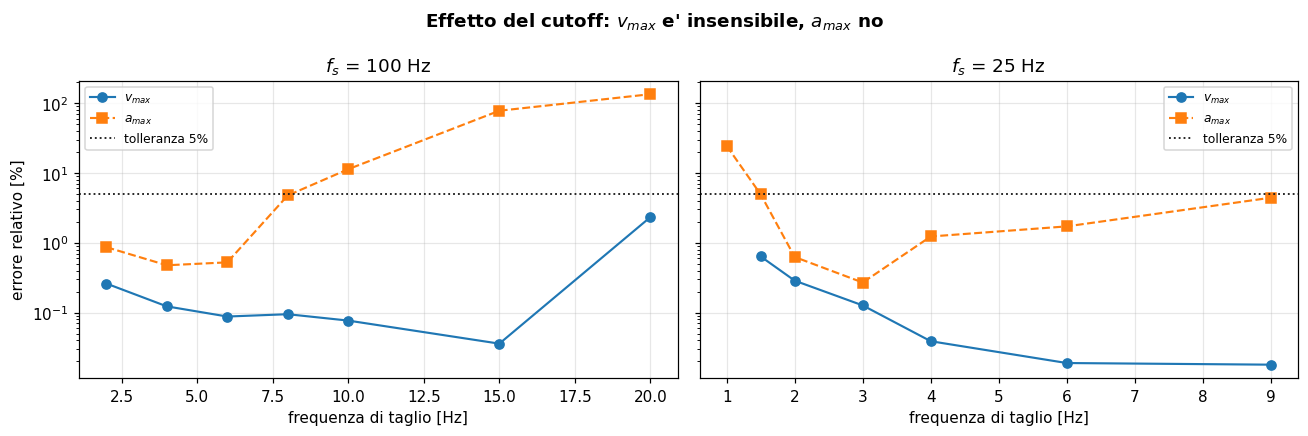

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, fs in zip(axes, (100.0, 25.0)):
    sub = cutoff_df[cutoff_df.fs == fs]
    ax.plot(sub.cutoff, sub.err_vmax, "o-", lw=1.4, ms=6, label="$v_{max}$")
    ax.plot(sub.cutoff, sub.err_amax, "s--", lw=1.4, ms=6, label="$a_{max}$")
    ax.axhline(5, color="#1a1a1a", ls=":", lw=1.2, label="tolleranza 5%")
    ax.set(xlabel="frequenza di taglio [Hz]", yscale="log",
           title=f"$f_s$ = {fs:g} Hz")
    ax.legend(fontsize=8)
axes[0].set_ylabel("errore relativo [%]")

fig.suptitle("Effetto del cutoff: $v_{max}$ e' insensibile, $a_{max}$ no",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "02_scelta_cutoff.png", dpi=150, bbox_inches="tight")
plt.show()

`vmax` è piatta su tutto l'intervallo: qualunque cutoff ragionevole va bene. `amax` ha
invece un minimo, e si degrada in entrambe le direzioni — per rumore a destra, per
deformazione delle rampe a sinistra.

La regola è in **rapporto** `fs/cutoff`, non in Hz assoluti: serve un fattore attorno a
15–20. Da qui i default: 6 Hz per i test sintetici a 100 Hz, 3 Hz per i dati reali a 25 Hz.

In [6]:
# Sui dati reali il valore vero non si conosce: si guarda la stabilita' della stima.
df = load_position_data(DATA_RAW / "1_50" / "mycobot280_angle_data.npy")
t_ses = df.iloc[:, 0].to_numpy()
nomi = list(df.columns[1:])
segmenti = segment_movements(t_ses, df[nomi].to_numpy(), joint_names=nomi)
seg = segmenti[0]          # j1, min -> max

righe = []
for cutoff in [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 8.0]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        r = analyze_joint_movement(time=seg.time, position=seg.position,
                                   cutoff_hz=cutoff)
    righe.append({
        "cutoff [Hz]": cutoff,
        "fs/cutoff": round(r.fs / cutoff, 1),
        "vmax [rad/s]": round(r.vmax_est, 4) if r.vmax_est else None,
        "amax [rad/s^2]": round(r.amax_est, 3) if r.amax_est else None,
        "regime [s]": round(r.steady_state_duration, 2),
        "amax affidabile": r.amax_reliable,
    })

pd.DataFrame(righe)
None

Sui dati reali lo stesso quadro per altra via: `vmax` cambia nella quarta cifra al variare
del cutoff, `amax` di parecchie unità percentuali. **Il limite non è la scelta del cutoff
ma la frequenza di campionamento**, e la pipeline se ne accorge da sé.

In [7]:
# --- soglie: le stime dipendono dai dati o dalla taratura? ------------------
default = PreprocessingConfig()
sweep = {
    "accel_threshold_ratio": [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50],
    "min_duration_ratio": [0.02, 0.05, 0.10, 0.15, 0.20, 0.30],
    "plateau_cv_max": [0.05, 0.10, 0.25, 0.40, 0.60],
    "max_gap_samples": [0, 1, 2, 3, 5, 8],
}

righe_soglie = []
for campo, valori in sweep.items():
    for valore in valori:
        cfg = PreprocessingConfig(**{campo: valore})
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = analyze_joint_movement(time=seg.time, position=seg.position,
                                       cutoff_hz=cfg.cutoff_hz, config=cfg)
        righe_soglie.append({"soglia": campo, "valore": valore,
                             "default": valore == getattr(default, campo),
                             "vmax": r.vmax_est,
                             "rilevato": r.steady_state_window is not None})

soglie_df = pd.DataFrame(righe_soglie)
rif = soglie_df[soglie_df.default].groupby("soglia").vmax.first()
soglie_df["scarto_%"] = soglie_df.apply(
    lambda r: 100 * abs(r.vmax - rif[r.soglia]) / rif[r.soglia]
    if pd.notna(r.vmax) else np.nan, axis=1)

sintesi_soglie = soglie_df.groupby("soglia").agg(
    valori_provati=("valore", "size"),
    intervallo=("valore", lambda s: f"{s.min():g} - {s.max():g}"),
    regime_sempre_rilevato=("rilevato", "all"),
    scarto_vmax_max_pct=("scarto_%", "max"),
).round(4)
sintesi_soglie.to_csv(TABLES / "02_sensibilita_soglie.csv")
print("Scarto massimo di vmax facendo variare una soglia per volta:")
sintesi_soglie

Scarto massimo di vmax facendo variare una soglia per volta:


,valori_provati,intervallo,regime_sempre_rilevato,scarto_vmax_max_pct
soglia,,,,
accel_threshold_ratio,7,0.1 - 0.5,True,0.0346
max_gap_samples,6,0 - 8,True,0.0000
min_duration_ratio,6,0.02 - 0.3,True,0.0000
plateau_cv_max,5,0.05 - 0.6,True,0.0000


`vmax` resta stabile entro frazioni di punto percentuale per tutte e quattro le soglie: il
valore identificato dipende dai **dati** e non dalla taratura.

## 3. Coerenza sui dati reali

Il valore vero non si conosce, ma due cose si verificano comunque: che la stessa
acquisizione ripetuta dia lo stesso numero, e che i due versi di marcia diano lo stesso
numero. La prima misura l'incertezza dell'intera catena, la seconda mette alla prova
l'ipotesi che il profilo sia puramente cinematico.

In [8]:
params = pd.read_csv(DATA_PROCESSED / "preprocessing_params.csv")

ripetibilita = params.groupby(["joint_name", "commanded_velocity"]).agg(
    n=("vmax_est", "size"),
    vmax_medio=("vmax_est", "mean"),
    vmax_std=("vmax_est", "std"),
).reset_index()
ripetibilita["cv_%"] = 100 * ripetibilita.vmax_std / ripetibilita.vmax_medio

per_velocita = ripetibilita.groupby("commanded_velocity").agg(
    celle=("cv_%", "size"), cv_medio=("cv_%", "mean"), cv_max=("cv_%", "max"),
).round(4)
print("Dispersione di vmax fra ripetizioni della stessa cella (giunto, velocita'):")
print(per_velocita.to_string())
print(f"\nCV mediano su tutte le celle: {ripetibilita['cv_%'].median():.3f}%")
ripetibilita.round(4).to_csv(TABLES / "02_ripetibilita.csv", index=False)

Dispersione di vmax fra ripetizioni della stessa cella (giunto, velocita'):
                    celle  cv_medio  cv_max
commanded_velocity                         
25                      6    0.1412  0.3241
50                      6    0.2182  0.3608
75                      6    0.2607  0.5314
100                     6    0.2003  0.2327

CV mediano su tutte le celle: 0.200%


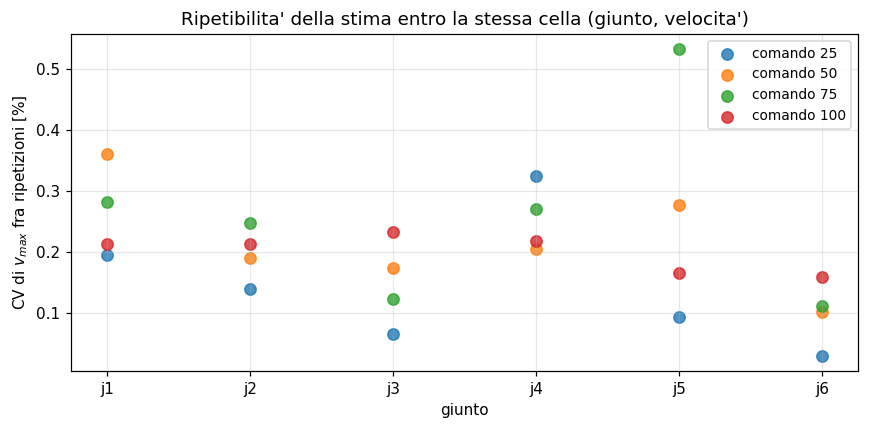

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))

for vel, gruppo in ripetibilita.groupby("commanded_velocity"):
    ax.scatter(gruppo.joint_name, gruppo["cv_%"], s=55, alpha=0.8,
               label=f"comando {int(vel)}")

ax.set(xlabel="giunto", ylabel="CV di $v_{max}$ fra ripetizioni [%]",
       title="Ripetibilita' della stima entro la stessa cella (giunto, velocita')")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "02_ripetibilita.png", dpi=150, bbox_inches="tight")
plt.show()

La dispersione fra ripetizioni resta ovunque **sotto l'1%**: è il limite superiore
dell'incertezza attribuibile a tutta la catena, e giustifica l'uso delle medie di cella nel
seguito. La velocità 25 ha una sola sessione, quindi lì il CV è calcolato su due valori.

In [10]:
params["verso"] = np.where(params.delta_q > 0, "positivo", "negativo")

avanti = params[params.verso == "positivo"].groupby(
    ["joint_name", "commanded_velocity"]).vmax_est.mean()
indietro = params[params.verso == "negativo"].groupby(
    ["joint_name", "commanded_velocity"]).vmax_est.mean()
comune = avanti.index.intersection(indietro.index)

asimmetria = 100 * (indietro[comune] - avanti[comune]).abs() / avanti[comune]
print(f"Asimmetria di vmax fra i due versi, su {len(comune)} celle:")
print(f"  mediana {asimmetria.median():.3f}%   massima {asimmetria.max():.3f}%")

per_giunto = asimmetria.groupby("joint_name").agg(["median", "max"]).round(4)
per_giunto.columns = ["mediana_%", "massima_%"]
per_giunto.to_csv(TABLES / "02_simmetria.csv")
per_giunto

Asimmetria di vmax fra i due versi, su 24 celle:
  mediana 0.161%   massima 0.459%


,mediana_%,massima_%
joint_name,,
j1,0.2355,0.4003
j2,0.1676,0.2616
j3,0.0606,0.0934
j4,0.3447,0.4594
j5,0.2172,0.4463
j6,0.0738,0.1491


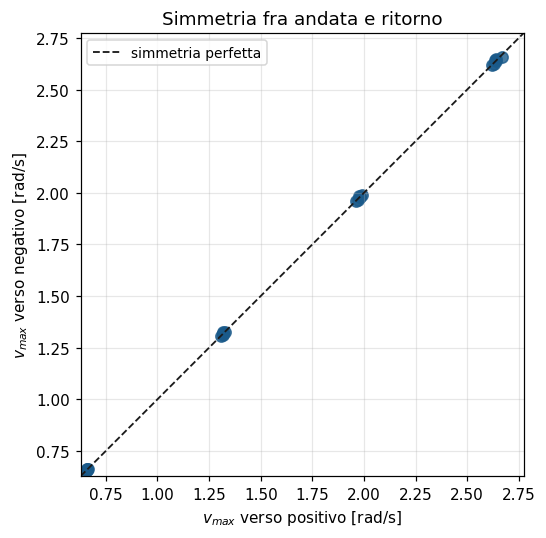

In [11]:
fig, ax = plt.subplots(figsize=(5.6, 5))

ax.scatter(avanti[comune], indietro[comune], s=55, alpha=0.8, color="#1a5a8a")
lim = [float(avanti[comune].min()) * 0.96, float(avanti[comune].max()) * 1.04]
ax.plot(lim, lim, "--", lw=1.2, color="#1a1a1a", label="simmetria perfetta")
ax.set(xlabel=r"$v_{max}$ verso positivo [rad/s]",
       ylabel=r"$v_{max}$ verso negativo [rad/s]",
       title="Simmetria fra andata e ritorno", xlim=lim, ylim=lim)
ax.set_aspect("equal")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "02_simmetria.png", dpi=150, bbox_inches="tight")
plt.show()

I punti cadono sulla bisettrice a tutte le velocità e per tutti i giunti, con asimmetria
mediana di pochi centesimi di punto percentuale: **nessun effetto direzionale sistematico**.

È un controllo che vale proprio perché è passato: su un braccio antropomorfo la gravità
agisce in verso opposto nelle due direzioni, e un controllore che ne risentisse avrebbe
lasciato traccia qui.

## Cosa portare in tesi

* Su profili sintetici a parametri noti la pipeline **ritrova i valori veri**: è la prova
  che il metodo funziona, ottenuta dove la risposta è verificabile.
* **`vmax` è robusta** a rumore, frequenza di taglio e scelta delle soglie; **`amax` no**,
  e la sua sensibilità è coerente con la sottostima dichiarata nel notebook `01`.
* **Ripetibilità** fra acquisizioni indipendenti sotto l'1%.
* **Nessuna asimmetria fra i due sensi di marcia.** È il dato che, nel notebook `03`,
  rende poco probabile la spiegazione gravitazionale dell'asimmetria fra accelerazione e
  decelerazione.